In [2]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ==========================================
# 1. DATASET LOADING & CLEANING
# ==========================================
print("--- Step 1: Loading and Cleaning Data ---")
# Loading the SMS Spam Collection dataset from the specified local path
file_path = "/content/SMSSpamCollection"
df = pd.read_csv(file_path, sep='\t', header=None, names=['label', 'message'])

print(f"Initial messages loaded: {len(df)}")
print(f"Missing values found: {df.isnull().sum().sum()}")

# Remove duplicates to match report specs
initial_len = len(df)
df = df.drop_duplicates().reset_index(drop=True)
duplicates_removed = initial_len - len(df)
print(f"Duplicate messages removed: {duplicates_removed}")
print(f"Messages after cleaning: {len(df)}")

# Encode labels: Spam = 1, Ham = 0
df['label_encoded'] = df['label'].map({'spam': 1, 'ham': 0})
ham_count = (df['label_encoded'] == 0).sum()
spam_count = (df['label_encoded'] == 1).sum()
print(f"Spam / Ham after cleaning: {spam_count} / {ham_count}\n")

# ==========================================
# 2. PRIOR PROBABILITIES & RANDOM VARIABLE ANALYSIS
# ==========================================
print("--- Step 2: Prior & Random Variable Analysis ---")
total_messages = len(df)
p_spam = spam_count / total_messages
p_ham = ham_count / total_messages

print(f"P(Spam) = {p_spam:.4f} ({p_spam*100:.2f}%)")
print(f"P(Ham) = {p_ham:.4f} ({p_ham*100:.2f}%)")

# Bernoulli Random Variable calculations
expected_value = p_spam
variance = p_spam * (1 - p_spam)
print(f"Expected Value E(Y) = {expected_value:.4f}")
print(f"Variance Var(Y) = {variance:.4f}\n")

# ==========================================
# 3. WORD-BASED PROBABILITY ANALYSIS
# ==========================================
print("--- Step 3: Word-Based Bayes Verification ---")
target_words = ['free', 'prize', 'win', 'urgent', 'offer']

for word in target_words:
    # Use regular expression for whole-word, case-insensitive matching
    pattern = rf'\b{word}\b'
    has_word = df['message'].str.contains(pattern, flags=re.IGNORECASE, regex=True)

    total_with_word = has_word.sum()
    spam_with_word = ((has_word) & (df['label_encoded'] == 1)).sum()

    # Conditional Probabilities
    p_word = total_with_word / total_messages
    p_word_given_spam = spam_with_word / spam_count

    # Direct vs Bayes Calculation
    p_spam_given_word_direct = spam_with_word / total_with_word if total_with_word > 0 else 0.0
    p_spam_given_word_bayes = (p_word_given_spam * p_spam) / p_word if p_word > 0 else 0.0

    print(f"Word: '{word}' | Total: {total_with_word} | Spam: {spam_with_word}")
    print(f"  -> P(Word|Spam) = {p_word_given_spam:.4f} | P(Word) = {p_word:.4f}")
    print(f"  -> P(Spam|Word) Direct = {p_spam_given_word_direct:.4f} | Bayes = {p_spam_given_word_bayes:.4f}\n")

# ==========================================
# 4. DATA PREPARATION & MODEL TRAINING
# ==========================================
print("--- Step 4: Model Training ---")
# 80/20 Stratified Split (Fixed from stratified to stratify)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df['message'],
    df['label_encoded'],
    test_size=0.20,
    random_state=42,
    stratify=df['label_encoded']
)

# Text Vectorization (Word counts)
vectorizer = CountVectorizer()
X_train = vectorizer.fit_transform(X_train_raw)
X_test = vectorizer.transform(X_test_raw)

print(f"Training Set Size: {X_train.shape[0]} | Testing Set Size: {X_test.shape[0]}")
print(f"Vocabulary Size: {len(vectorizer.get_feature_names_out())}")

# Multinomial Naive Bayes Model
model = MultinomialNB()
model.fit(X_train, y_train)
print("Model trained successfully!\n")

# ==========================================
# 5. EVALUATION
# ==========================================
print("--- Step 5: Evaluation Performance ---")
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Overall Test Accuracy: {accuracy*100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Ham', 'Spam']))

# Confusion Matrix breakdown
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print("Confusion Matrix Metrics:")
print(f"  True Negatives (Ham -> Ham): {tn}")
print(f"  True Positives (Spam -> Spam): {tp}")
print(f"  False Positives (Ham -> Spam): {fp}")
print(f"  False Negatives (Spam -> Ham): {fn}\n")

# ==========================================
# 6. REAL-TIME TESTING DEMO FUNCTION
# ==========================================
print("--- Step 6: Live Demo Predictor ---")
def predict_message(message_text):
    # Vectorize sample text using existing vectorizer configurations
    vectorized_text = vectorizer.transform([message_text])
    prediction_class = model.predict(vectorized_text)[0]
    probabilities = model.predict_proba(vectorized_text)[0]

    label_mapping = {0: "Ham", 1: "Spam"}

    print(f"Message: \"{message_text}\"")
    print(f"Prediction: {label_mapping[prediction_class]}")
    print(f"P(Ham|Message):  {probabilities[0]:.6f}")
    print(f"P(Spam|Message): {probabilities[1]:.6f}")
    print("-" * 50)

# Running report sample test cases
predict_message("Congratulations! You have won a free prize. Claim now.")
predict_message("Hey, are we still meeting for lunch tomorrow?")
predict_message("URGENT! Your mobile number has won a £2000 prize. Call now to claim.")
predict_message("Can you send me the notes from today's class?")

# ==========================================
# 7. GENERATING CHARTS FOR VISUAL DEMO
# ==========================================
# Plot 1: Class Distribution
plt.figure(figsize=(6, 4))
plt.bar(['Ham (0)', 'Spam (1)'], [ham_count, spam_count], color=['grey', 'black'], edgecolor='black')
plt.title('Class Distribution (after de-duplication)')
plt.ylabel('Number of messages')
for i, val in enumerate([ham_count, spam_count]):
    plt.text(i, val + 50, str(val), ha='center', va='bottom')
plt.tight_layout()
plt.savefig('class_distribution.png')
plt.close()

# Plot 2: Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greys', cbar=False,
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'],
            annot_kws={"size": 16})
plt.title('Confusion Matrix (Test Set)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.close()

print("Demo charts saved as 'class_distribution.png' and 'confusion_matrix.png'!")

--- Step 1: Loading and Cleaning Data ---
Initial messages loaded: 5572
Missing values found: 0
Duplicate messages removed: 403
Messages after cleaning: 5169
Spam / Ham after cleaning: 653 / 4516

--- Step 2: Prior & Random Variable Analysis ---
P(Spam) = 0.1263 (12.63%)
P(Ham) = 0.8737 (87.37%)
Expected Value E(Y) = 0.1263
Variance Var(Y) = 0.1104

--- Step 3: Word-Based Bayes Verification ---
Word: 'free' | Total: 203 | Spam: 148
  -> P(Word|Spam) = 0.2266 | P(Word) = 0.0393
  -> P(Spam|Word) Direct = 0.7291 | Bayes = 0.7291

Word: 'prize' | Total: 73 | Spam: 73
  -> P(Word|Spam) = 0.1118 | P(Word) = 0.0141
  -> P(Spam|Word) Direct = 1.0000 | Bayes = 1.0000

Word: 'win' | Total: 55 | Spam: 49
  -> P(Word|Spam) = 0.0750 | P(Word) = 0.0106
  -> P(Spam|Word) Direct = 0.8909 | Bayes = 0.8909

Word: 'urgent' | Total: 62 | Spam: 57
  -> P(Word|Spam) = 0.0873 | P(Word) = 0.0120
  -> P(Spam|Word) Direct = 0.9194 | Bayes = 0.9194

Word: 'offer' | Total: 30 | Spam: 24
  -> P(Word|Spam) = 0.036

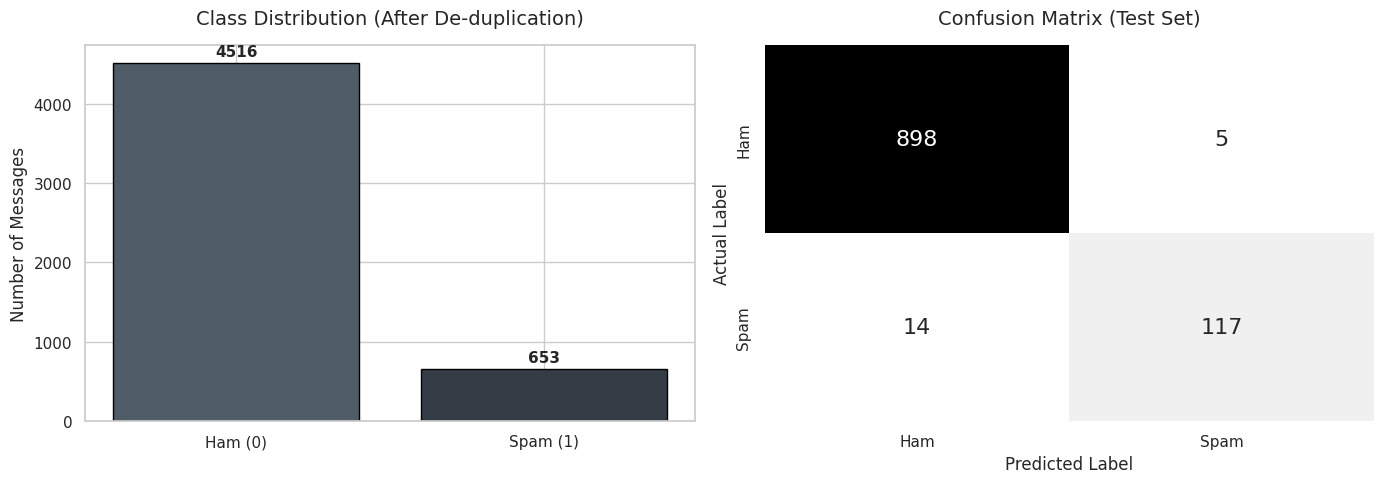

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Set style
sns.set_theme(style="whitegrid")

# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Class Distribution
axes[0].bar(['Ham (0)', 'Spam (1)'], [ham_count, spam_count], color=['#4f5b66', '#343d46'], edgecolor='black')
axes[0].set_title('Class Distribution (After De-duplication)', fontsize=14, pad=15)
axes[0].set_ylabel('Number of Messages', fontsize=12)
for i, val in enumerate([ham_count, spam_count]):
    axes[0].text(i, val + 50, str(val), ha='center', va='bottom', fontsize=11, fontweight='bold')

# Plot 2: Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greys', cbar=False,
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'],
            annot_kws={"size": 16}, ax=axes[1])
axes[1].set_title('Confusion Matrix (Test Set)', fontsize=14, pad=15)
axes[1].set_xlabel('Predicted Label', fontsize=12)
axes[1].set_ylabel('Actual Label', fontsize=12)

plt.tight_layout()
plt.show()

In [4]:
def calculate_spam_probability_given_word(word):
    pattern = rf'\b{word}\b'
    has_word = df['message'].str.contains(pattern, flags=re.IGNORECASE, regex=True)

    total_with_word = has_word.sum()
    spam_with_word = ((has_word) & (df['label_encoded'] == 1)).sum()

    if total_with_word == 0:
        print(f"The word '{word}' was not found in any messages in the dataset.")
        return

    p_word = total_with_word / total_messages
    p_word_given_spam = spam_with_word / spam_count
    p_spam_given_word_bayes = (p_word_given_spam * p_spam) / p_word

    print(f"--- Probability Analysis for '{word}' ---")
    print(f"Total occurrences: {total_with_word}")
    print(f"Occurrences in Spam: {spam_with_word} ({spam_with_word/total_with_word*100:.2f}%)")
    print(f"P(Spam | '{word}') = {p_spam_given_word_bayes:.4f} ({p_spam_given_word_bayes*100:.2f}%)")

# Let's test it with a custom suspicious word like 'claim'
calculate_spam_probability_given_word('claim')

--- Probability Analysis for 'claim' ---
Total occurrences: 92
Occurrences in Spam: 92 (100.00%)
P(Spam | 'claim') = 1.0000 (100.00%)


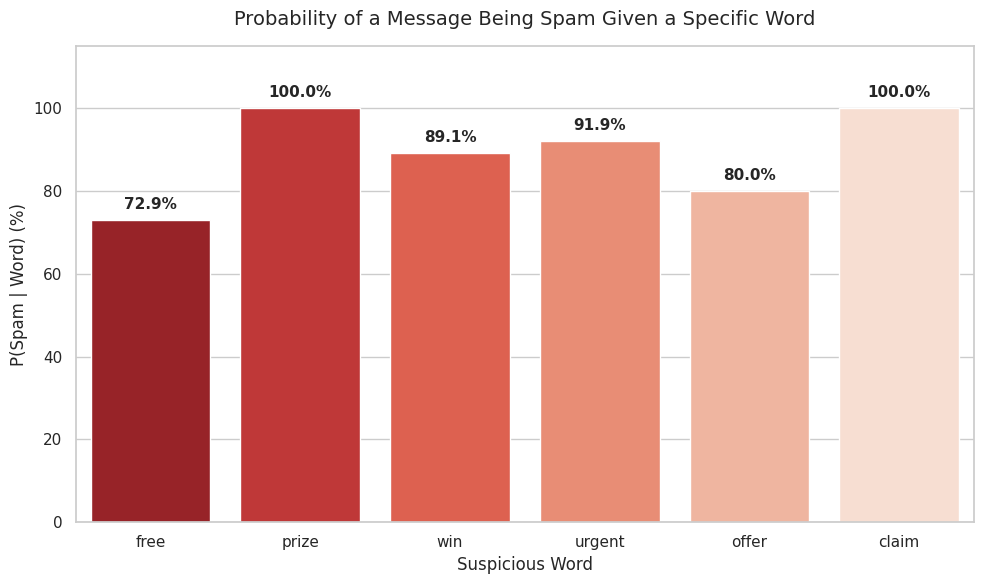

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import re

# List of words to analyze
words_to_plot = ['free', 'prize', 'win', 'urgent', 'offer', 'claim']
probabilities = []

# Calculate P(Spam | Word) for each word
for w in words_to_plot:
    pattern = rf'\b{w}\b'
    has_word = df['message'].str.contains(pattern, flags=re.IGNORECASE, regex=True)
    total_with_word = has_word.sum()
    spam_with_word = ((has_word) & (df['label_encoded'] == 1)).sum()

    prob = (spam_with_word / total_with_word) if total_with_word > 0 else 0.0
    probabilities.append(prob * 100) # Convert to percentage

# Create the bar plot
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")
ax = sns.barplot(x=words_to_plot, y=probabilities, palette="Reds_r", hue=words_to_plot, legend=False)

# Add details
plt.title('Probability of a Message Being Spam Given a Specific Word', fontsize=14, pad=15)
plt.xlabel('Suspicious Word', fontsize=12)
plt.ylabel('P(Spam | Word) (%)', fontsize=12)
plt.ylim(0, 115)

# Annotate percentages on top of bars
for i, p in enumerate(probabilities):
    ax.text(i, p + 2, f"{p:.1f}%", ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()